# Quiz 2：訓練 CNN / Training and Evaluation

**蘇芯儀 / Sharon0726**

此 Notebook 讀取實際完成的 6 組實驗，不以展示數值取代訓練。

In [1]:
# 子目標：定位作業目錄，讀取已完成的真實實驗結果。
from pathlib import Path
import csv, json
import numpy as np
from IPython.display import display, Markdown, Image
ROOT = Path.cwd()
if not (ROOT / "results" / "metrics.json").exists():
    raise FileNotFoundError("請在 Week3 作業目錄開啟 Notebook。")
R = ROOT / "results"
metrics = json.loads((R / "metrics.json").read_text())
selected = json.loads((R / "selection.json").read_text())["selected"]
classes = json.loads((R / "classes.json").read_text())
def table(rows, columns):
    text = "| " + " | ".join(columns) + " |\n| " + " | ".join(["---"]*len(columns)) + " |\n"
    for row in rows:
        text += "| " + " | ".join(str(row[c]) for c in columns) + " |\n"
    display(Markdown(text))
def figure(name):
    display(Image(filename=str(R / "figures" / name)))


## Quiz 2：訓練與比較（基礎 30＋進階 20 分）

### 自訂 Plain CNN

自行實作三個串接 block：`Conv3×3 → ReLU → MaxPool2×2`，通道為 3→16→32→64；padding=1，卷積含 bias。沒有 shortcut、residual 或預訓練權重。

| 階段 | 輸出尺寸 |
|---|---|
| Input | 3×32×32 |
| Block 1 | 16×16×16 |
| Block 2 | 32×8×8 |
| Block 3 | 64×4×4 |
| Flatten → Linear → ReLU | 128 |
| Linear | 10 logits |

### 經典 CNN：ResNet-18 Transfer Learning

採 [ResNet](https://arxiv.org/abs/1512.03385) 的 ResNet-18 與官方 `ResNet18_Weights.IMAGENET1K_V1`。凍結整個預訓練 Backbone，將 1,000-class FC 換成 `Linear(512,10)`；只訓練新的 head。Backbone 永遠保持 `eval()`，BatchNorm running statistics 也固定。

每張影像的 frozen feature 可預先計算；快取的是影像經完整 Backbone 後的 512 維向量。訓練線性 head 等價於凍結 Backbone 後訓練完整模型的 head，不是用未訓練模型代替 Transfer Learning。已驗證重新組合 Backbone＋head 的 end-to-end 機率與快取推論一致。

64×64 是本實驗控制計算量的設計，與權重官方預設的 224×224 評估流程不同；此報告不宣稱復現 ImageNet 官方數值。模型間也同時存在預訓練、解析度、深度等差異，因此不能把表現差異全歸因於 residual connection。

### 超參數實驗設計

兩個模型各比較兩種 learning rate，其他條件在各模型內固定。初始化 seed、每個 epoch 的 shuffle order、split、batch size、optimizer、weight decay 均固定。optimizer=AdamW，cross-entropy loss（直接輸入 logits），batch size=128，weight decay=0.0001；不使用 learning-rate scheduler、early stopping、label smoothing 或 Mixup。

| 模型 | Learning rates | Epochs／run | 訓練部分 |
|---|---|---:|---|
| Plain CNN | 0.001、0.0003 | 15 | 全部權重 |
| ResNet-18 | 0.001、0.003 | 25 | 新增的 512→10 head |

每次 run 保留 validation Top-1 最高的 epoch；同分取最早 epoch。先從兩個無擴增設定選 baseline，再以該 learning rate 加入擴增。最終在 baseline 與 augmentation 間依 validation 選擇；同分選 baseline。**所有決策寫入 `selection.json` 後，才首次對 test 做推論。** 六組 test 結果均報告，沒有利用 test 排名選模型。

| Run | Learning rate | Augmentation | Best epoch | Val Top-1 | Val Top-5 | Test Top-1 | Test Top-5 | Macro-AUC |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| plain_lr0.001_base | 0.001 | False | 14/15 | 72.58% | 97.54% | 72.47% | 98.09% | 0.9607 |
| plain_lr0.0003_base | 0.0003 | False | 15/15 | 67.98% | 97.18% | 67.88% | 97.30% | 0.9486 |
| plain_lr0.001_aug | 0.001 | True | 14/15 | 75.24% | 98.18% | 74.68% | 98.34% | 0.9669 |
| resnet_lr0.001_base | 0.001 | False | 9/25 | 76.74% | 98.60% | 76.26% | 98.63% | 0.9709 |
| resnet_lr0.003_base | 0.003 | False | 2/25 | 76.00% | 98.28% | 75.55% | 98.61% | 0.9690 |
| resnet_lr0.001_aug | 0.001 | True | 20/25 | 76.08% | 98.42% | 75.31% | 98.48% | 0.9695 |

- **plain**：learning rate=0.001 的最佳 validation Top-1 為 72.58%，另一設定 0.0003 為 67.98%。因此採用前者進行擴增對照；這是固定預算下的 learning-rate 比較，不代表搜尋到全域最佳超參數。
- **resnet**：learning rate=0.001 的最佳 validation Top-1 為 76.74%，另一設定 0.003 為 76.00%。因此採用前者進行擴增對照；這是固定預算下的 learning-rate 比較，不代表搜尋到全域最佳超參數。


訓練曲線中的 train loss／Top-1 是各 batch 更新過程的加權平均，validation 則在 epoch 結束後以同一個 checkpoint 評估；兩者不是完全同時點的量測。曲線呈現收斂與過擬合跡象，但不作為額外調參回饋。

### Testing Dataset 預測與指標

每個 run 預測全部 10,000 張 official test images。`results/predictions/*.csv` 包含 test_index、true_class、predicted_class、Top-1／Top-5 是否命中、五個候選類別及 **10 類 softmax 機率**；另存 `.npz` 方便精確重算。不同模型的相同行對應同一張測試影像。

- Top-1 Accuracy：最高分的類別等於真實類別的比例。
- Top-5 Accuracy：真實類別出現在前五名的比例。本資料有 10 類，因此 Top-5 不會必然是 100%。
- ROC：每類各自做 One-vs-Rest，以該類 softmax score 排序，不能以 argmax label 取代。
- Macro-AUC：10 個 class-wise AUC 的算術平均；此處不是 micro 或 weighted AUC，也不是先畫平均 ROC 再積分。

| Class | Plain CNN AUC | ResNet-18 AUC |
| --- | --- | --- |
| airplane | 0.9732 | 0.9775 |
| automobile | 0.9901 | 0.9869 |
| bird | 0.9409 | 0.9519 |
| cat | 0.9237 | 0.9437 |
| deer | 0.9626 | 0.9615 |
| dog | 0.9500 | 0.9604 |
| frog | 0.9796 | 0.9799 |
| horse | 0.9761 | 0.9751 |
| ship | 0.9874 | 0.9878 |
| truck | 0.9852 | 0.9844 |



每個實驗都有 10 條 ROC，且 `results/roc/*.csv` 儲存 FPR、TPR 與 threshold。AUC 衡量類別分數的排序區分能力；Top-1 要求真實類別超過其他所有類別，兩者意義不同。

- **plain** 最多的三種錯誤（真實 → 預測）為：cat → dog：254 張；truck → automobile：114 張；dog → cat：110 張。
- **resnet** 最多的三種錯誤（真實 → 預測）為：dog → cat：173 張；truck → automobile：113 張；deer → bird：106 張。


### Accuracy 與參數量

Plain CNN 共 **156,074** 個參數，全部可訓練。ResNet-18 共 **11,181,642** 個參數，但只更新 **5,130** 個 head 參數。trainable parameters 少不代表推論模型小：ResNet 仍須儲存並執行完整 Backbone。

最終 test Top-1 差異為 ResNet 減 Plain **+1.58 pp**。這是兩個完整訓練方案的實測比較，並非只比較架構的嚴格消融。



In [2]:
# 子目標：呈現可執行的自訂架構及全部實驗結果。
from models import PlainCNN
print(PlainCNN())
rows = [{"run": r["run"], "best_epoch": r["best_epoch"],
         "val_Top1": f"{r['val_top1']:.2%}", "test_Top1": f"{r['test_top1']:.2%}",
         "test_Top5": f"{r['test_top5']:.2%}", "Macro_AUC": f"{r['test_macro_auc']:.4f}",
         "total_params": r["parameters_total"], "trainable_params": r["parameters_trainable"]}
        for r in metrics]
table(rows, list(rows[0]))

PlainCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (head): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1024, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


| run | best_epoch | val_Top1 | test_Top1 | test_Top5 | Macro_AUC | total_params | trainable_params |
| --- | --- | --- | --- | --- | --- | --- | --- |
| plain_lr0.001_base | 14 | 72.58% | 72.47% | 98.09% | 0.9607 | 156074 | 156074 |
| plain_lr0.0003_base | 15 | 67.98% | 67.88% | 97.30% | 0.9486 | 156074 | 156074 |
| plain_lr0.001_aug | 14 | 75.24% | 74.68% | 98.34% | 0.9669 | 156074 | 156074 |
| resnet_lr0.001_base | 9 | 76.74% | 76.26% | 98.63% | 0.9709 | 11181642 | 5130 |
| resnet_lr0.003_base | 2 | 76.00% | 75.55% | 98.61% | 0.9690 | 11181642 | 5130 |
| resnet_lr0.001_aug | 20 | 76.08% | 75.31% | 98.48% | 0.9695 | 11181642 | 5130 |


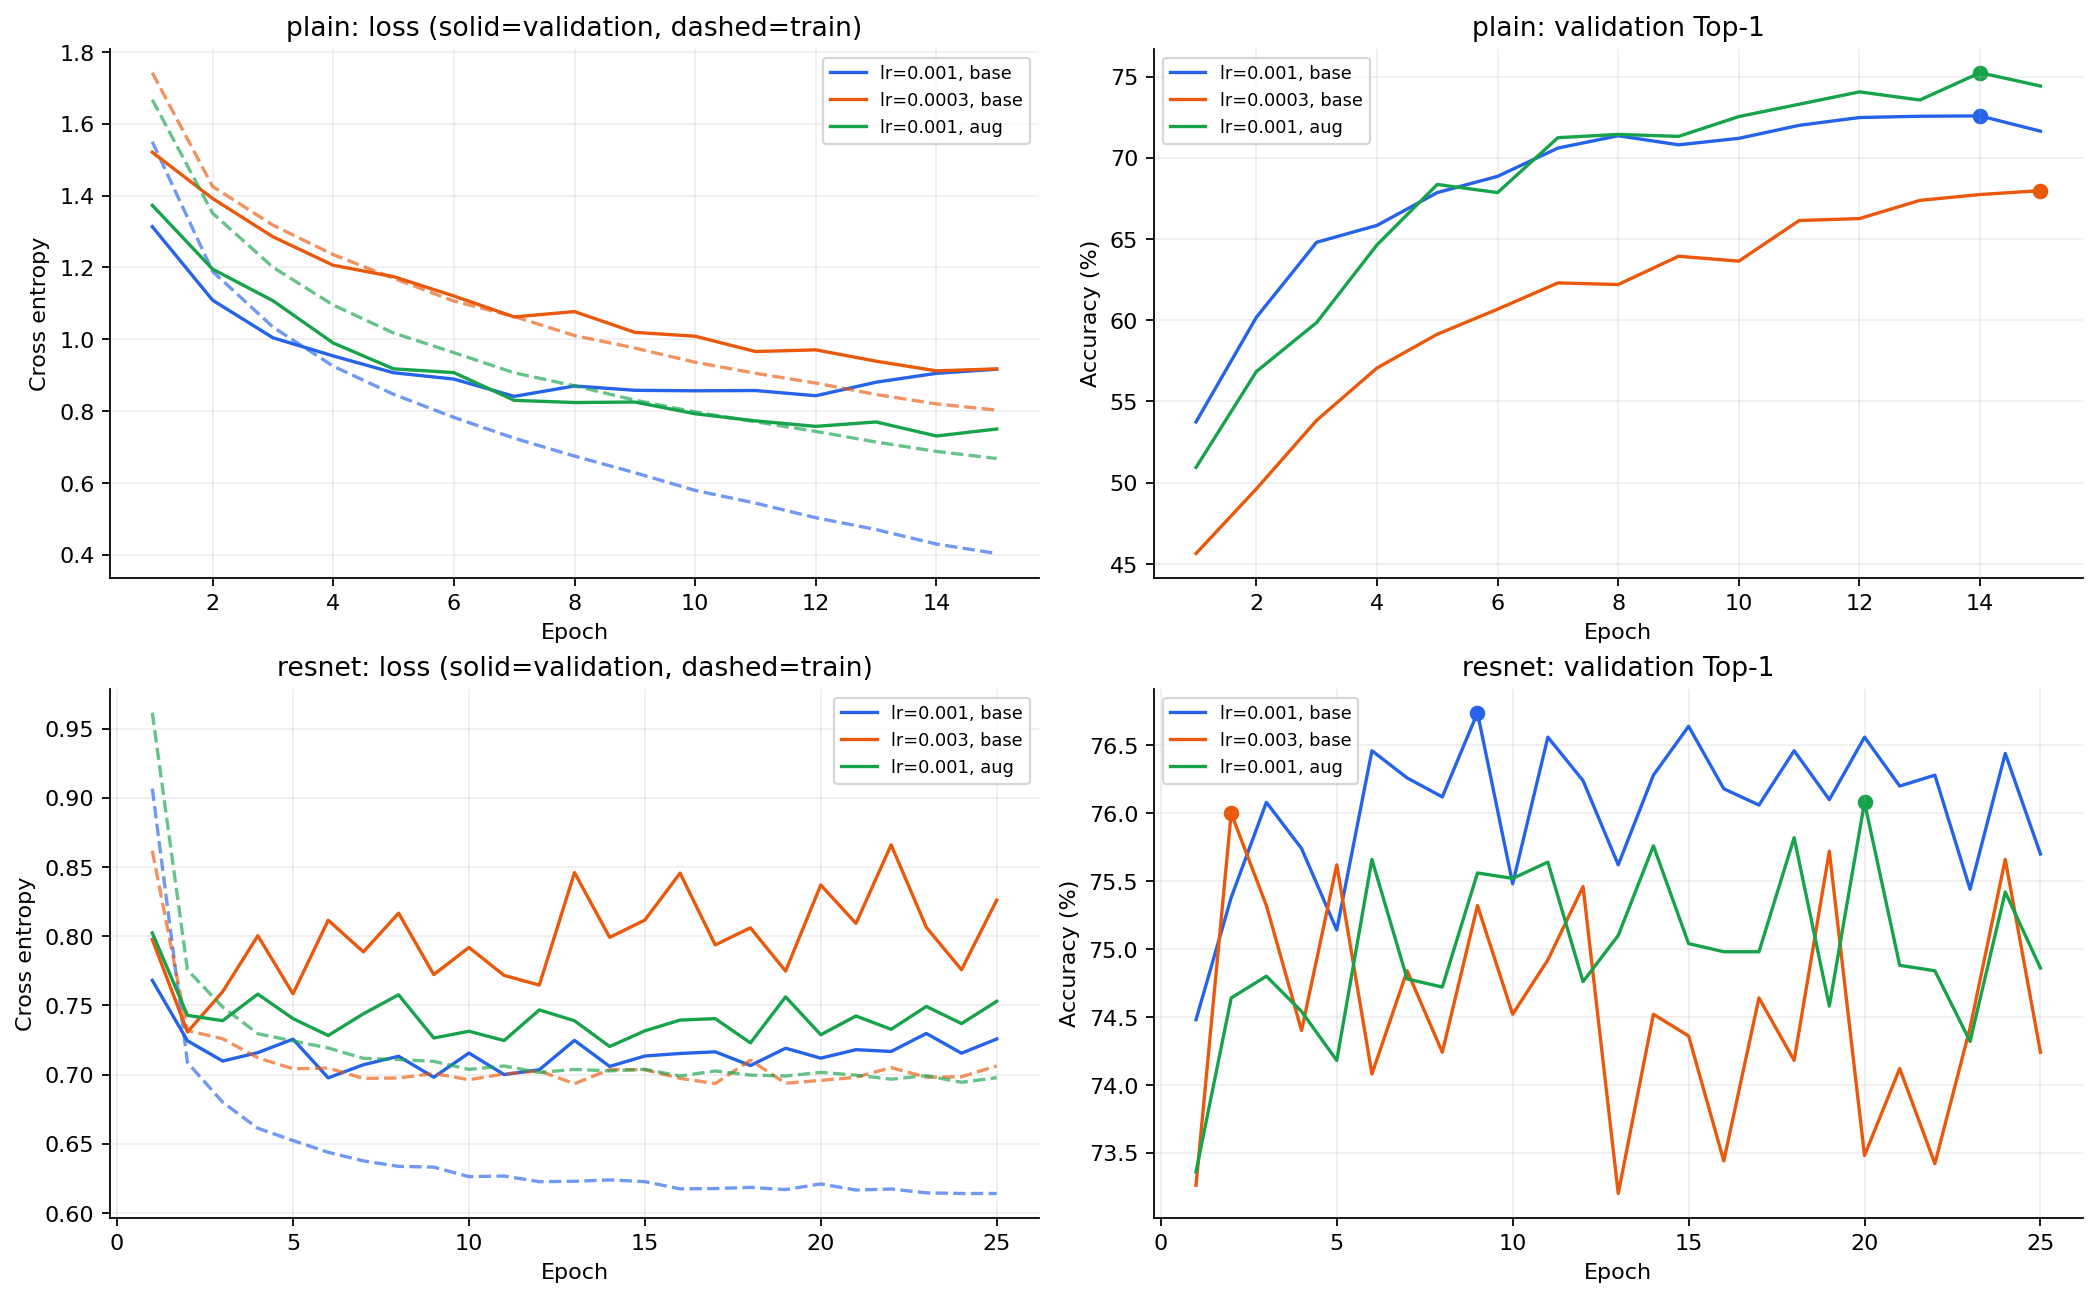

{
  "plain": {
    "baseline": "plain_lr0.001_base",
    "augmented": "plain_lr0.001_aug",
    "final": "plain_lr0.001_aug"
  },
  "resnet": {
    "baseline": "resnet_lr0.001_base",
    "augmented": "resnet_lr0.001_aug",
    "final": "resnet_lr0.001_base"
  }
}


In [3]:
# 子目標：觀察收斂與驗證集選模。
figure("learning_curves.png")
print(json.dumps(selected, indent=2))

plain_lr0.001_aug samples: 10000
Top-1: 0.7468 Top-5: 0.9834
Macro-AUC: 0.9668784944444445


| test_index | truth | prediction | top5 |
| --- | --- | --- | --- |
| 0 | cat | cat | cat, dog, ship, frog, truck |
| 1 | ship | ship | ship, automobile, airplane, truck, bird |
| 2 | ship | ship | ship, automobile, airplane, truck, cat |
| 3 | airplane | airplane | airplane, ship, bird, deer, cat |
| 4 | frog | frog | frog, bird, cat, deer, ship |


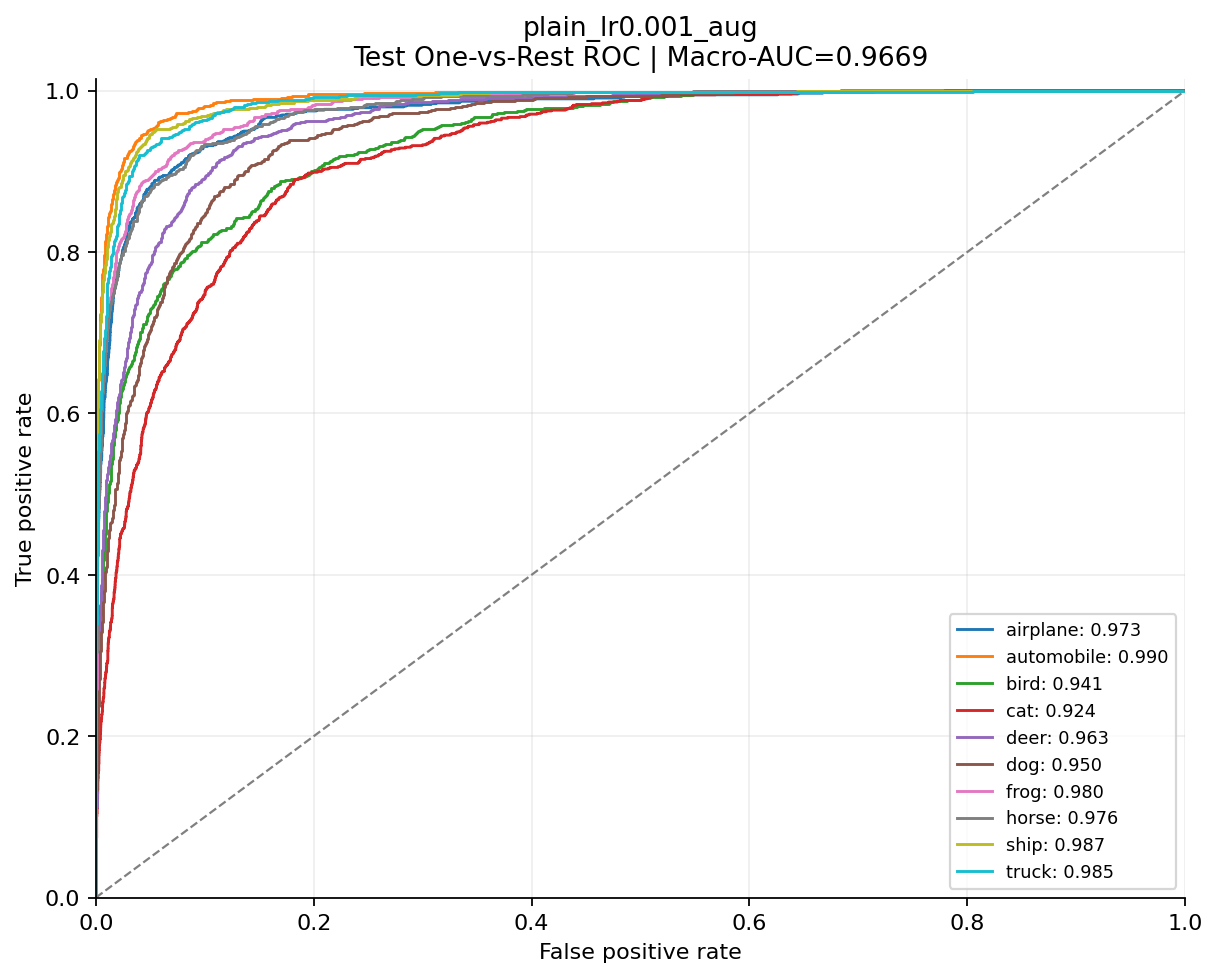

resnet_lr0.001_base samples: 10000
Top-1: 0.7626 Top-5: 0.9863


Macro-AUC: 0.9709126888888889


| test_index | truth | prediction | top5 |
| --- | --- | --- | --- |
| 0 | cat | cat | cat, dog, automobile, truck, bird |
| 1 | ship | ship | ship, automobile, airplane, bird, truck |
| 2 | ship | ship | ship, airplane, automobile, truck, horse |
| 3 | airplane | ship | ship, airplane, cat, truck, bird |
| 4 | frog | frog | frog, bird, deer, cat, dog |


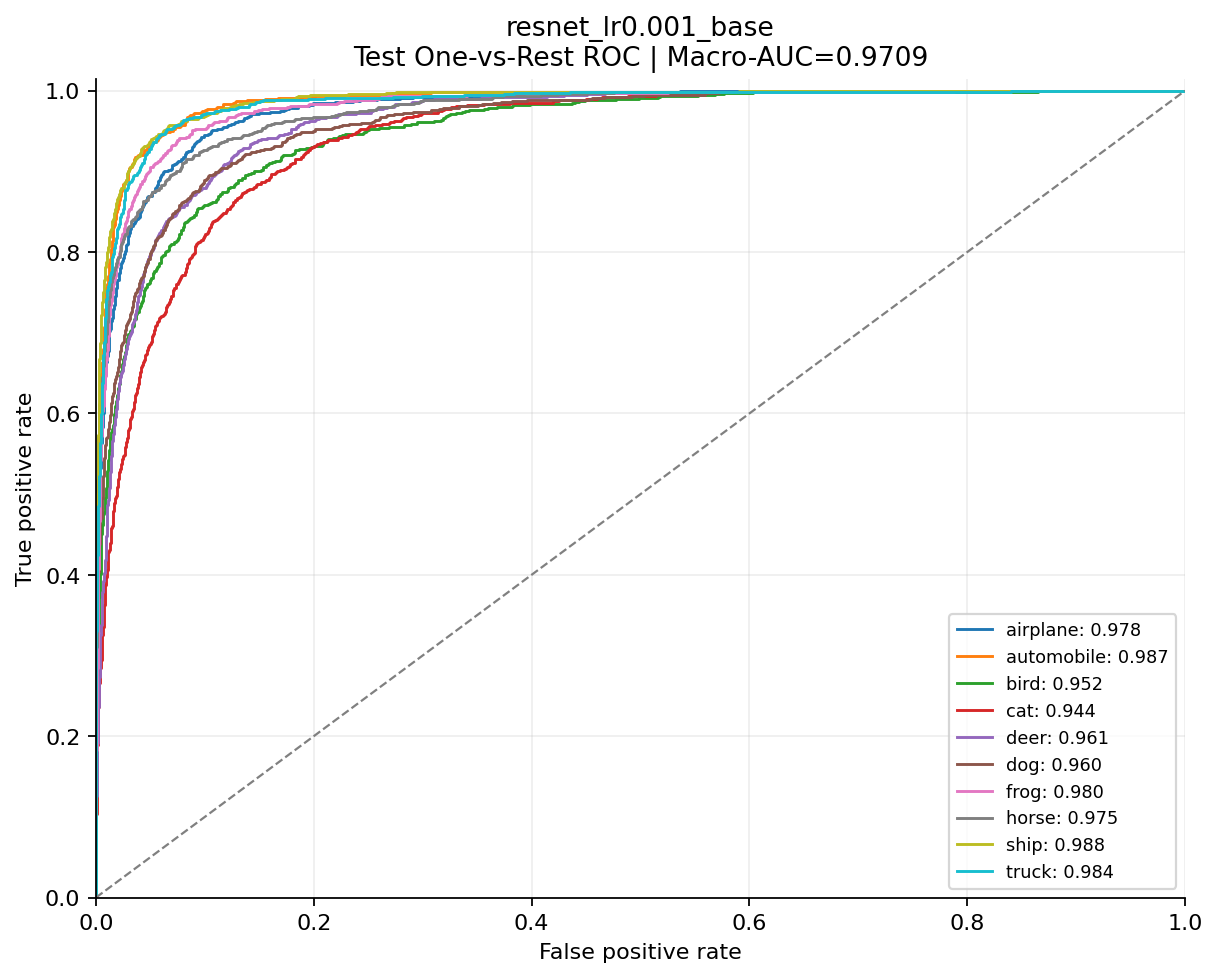

In [4]:
# 子目標：用所有 test scores 獨立重算指標，並展示前五筆預測。
from sklearn.metrics import roc_auc_score
for family in ["plain", "resnet"]:
    name = selected[family]["final"]
    arrays = np.load(R / "predictions" / f"{name}.npz")
    p, y = arrays["probabilities"], arrays["labels"]
    order = np.argsort(-p, axis=1)
    print(name, "samples:", len(y))
    print("Top-1:", (order[:, 0] == y).mean(), "Top-5:", (order[:, :5] == y[:, None]).any(1).mean())
    print("Macro-AUC:", np.mean([roc_auc_score(y == c, p[:, c]) for c in range(10)]))
    table([{"test_index": i, "truth": classes[y[i]], "prediction": classes[order[i, 0]],
            "top5": ", ".join(classes[j] for j in order[i, :5])} for i in range(5)],
          ["test_index", "truth", "prediction", "top5"])
    figure(f"roc_{name}.png")

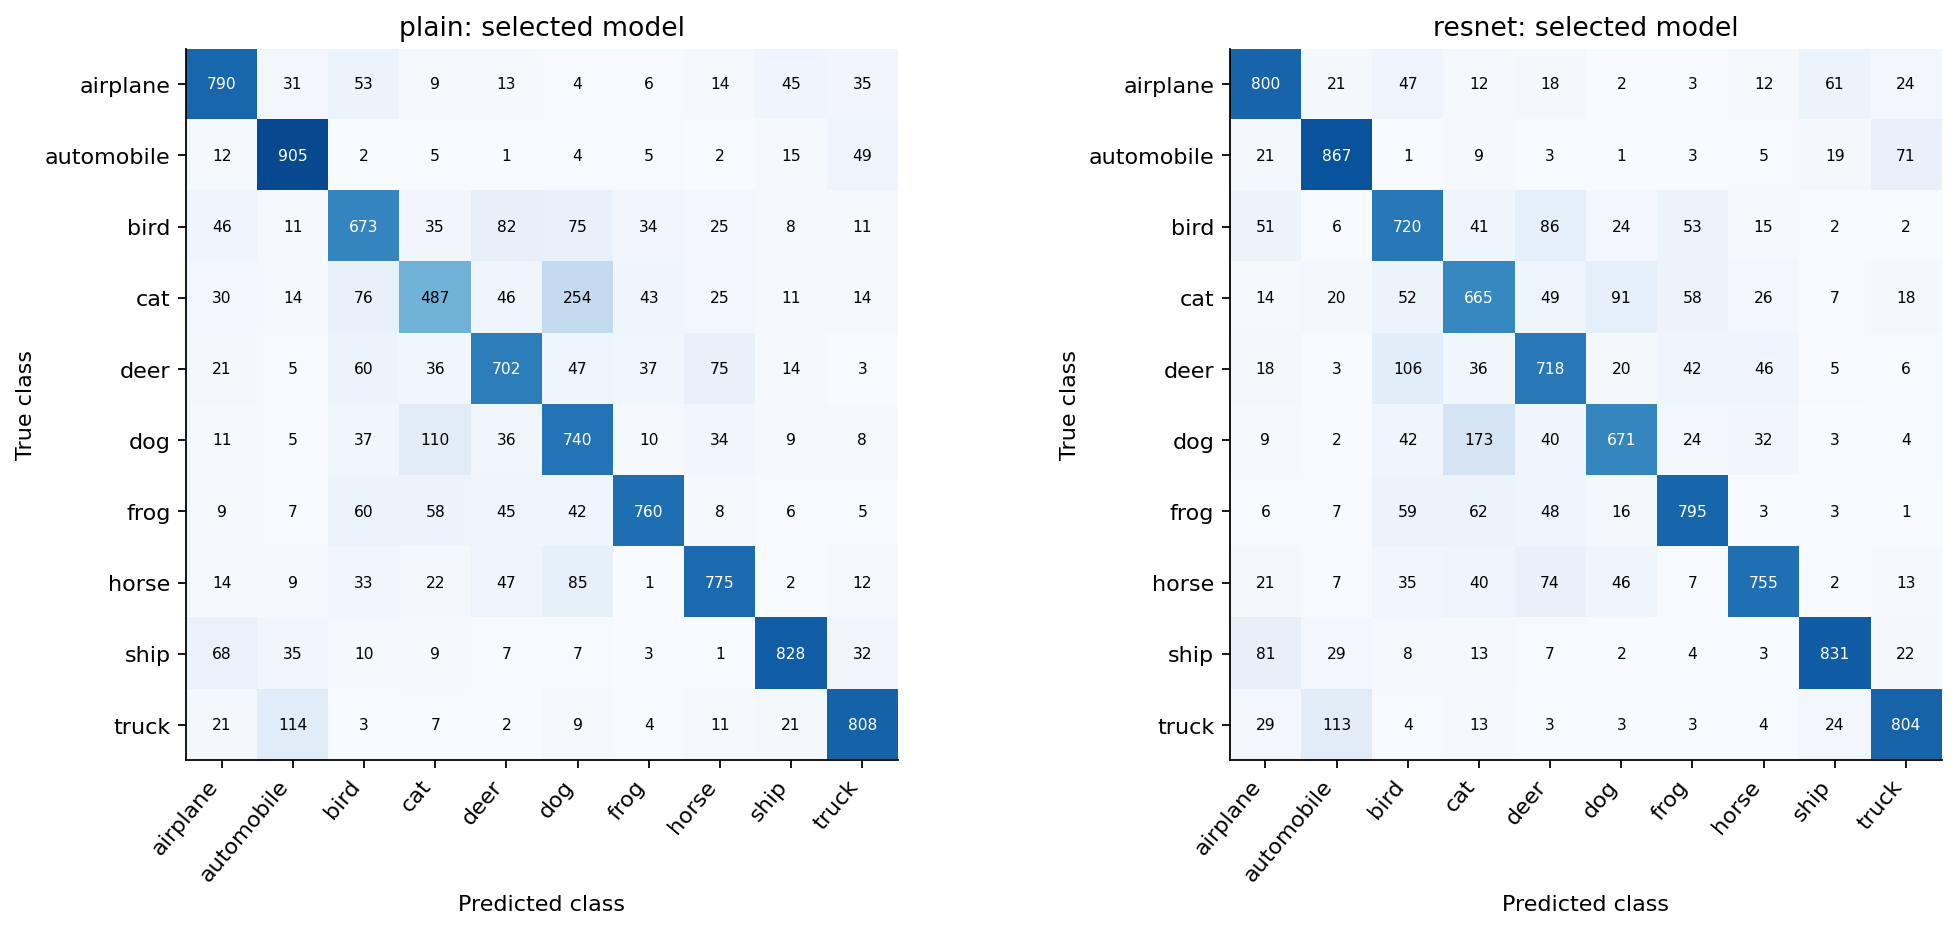

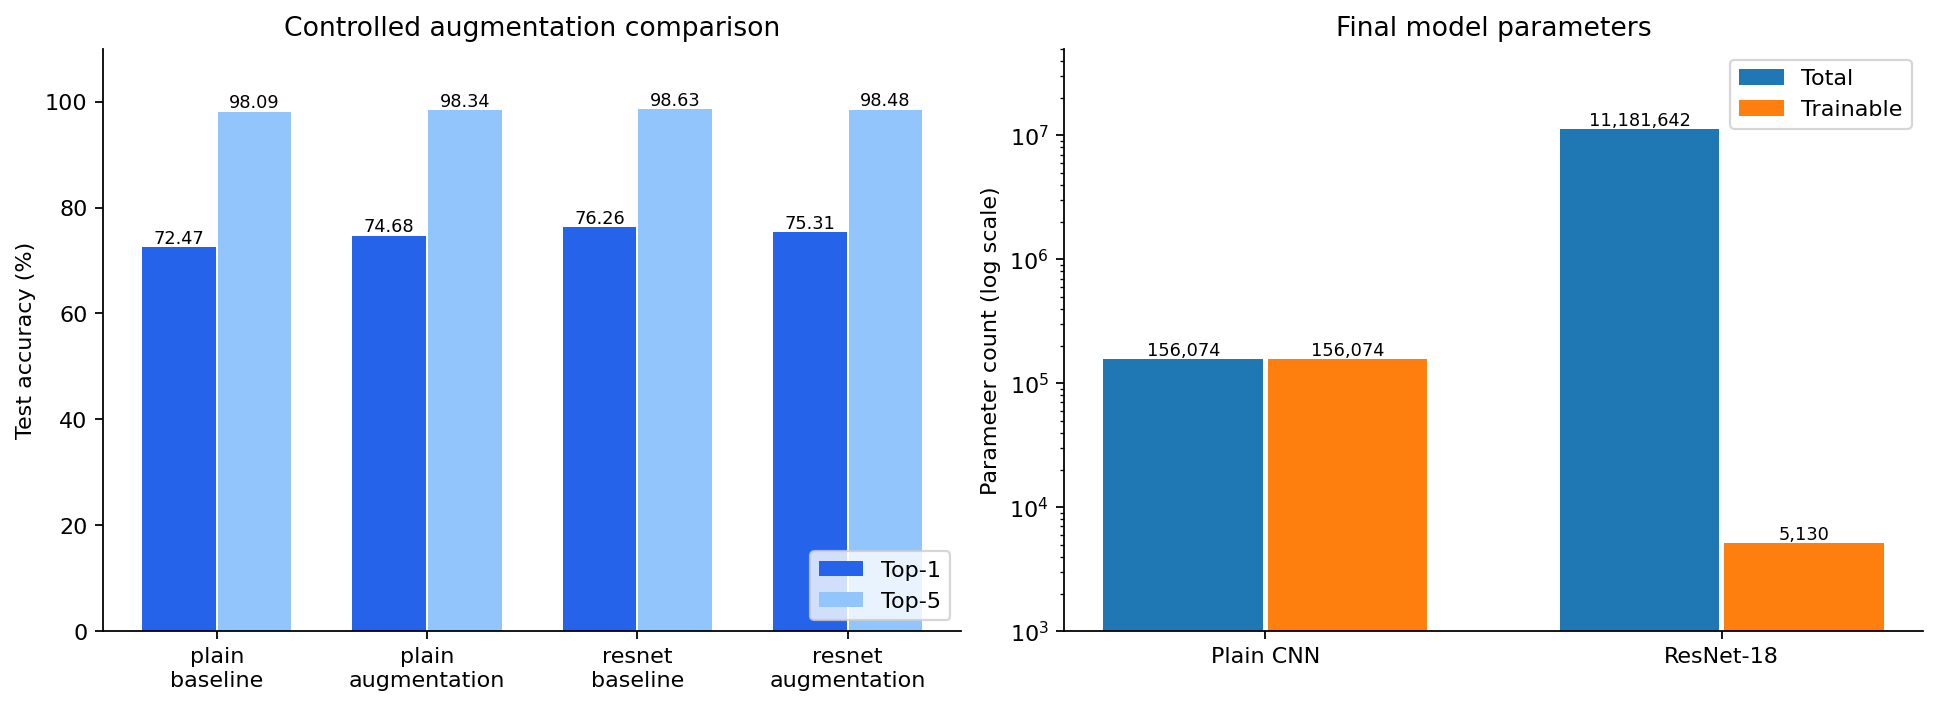

In [5]:
# 子目標：比較類別錯誤分布、準確率與參數量。
figure("confusion_matrices.png")
figure("model_comparison.png")